In [49]:
import pandas as pd

df = pd.read_csv('/diabetes.csv')

print('Dataset loaded successfully')
display(df.head())

Dataset loaded successfully


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [51]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [52]:
df.describe()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


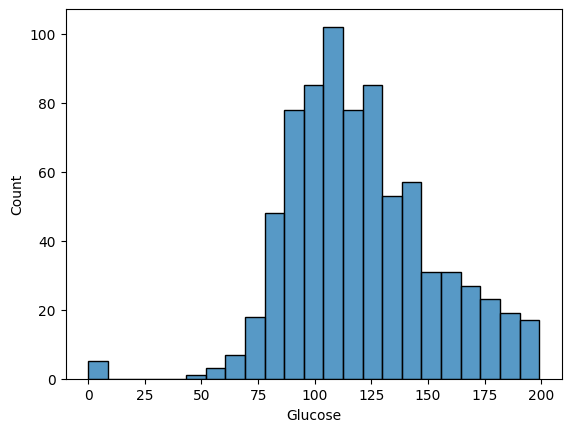

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(data=df,x='Glucose')
plt.show()



A histogram was used to examine the distribution of the glucose measuements in the Pima Indians Diabetes dataset. It illustrates glucose counts in the data, showing approximate values between 80 and 180 with few observations at higher and lower values. The graph also shows a positive skew. The zero value may represent missing measurements, and would be investegated during data cleaning.

In [54]:
from sklearn.model_selection import train_test_split

x = df.drop('Outcome',axis=1)
y = df['Outcome']

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

print('Training data',x_train.shape)
print('Testing data',x_test.shape)


Training data (614, 8)
Testing data (154, 8)


In [55]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(x_train,y_train)

y_pred = model.predict(x_test)

print('Model training and predictioncompleted.')

Model training and predictioncompleted.


In [56]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

print('accuracy:',accuracy_score(y_test,y_pred))
print('precision:',precision_score (y_test,y_pred))
print('recall:',recall_score(y_test,y_pred))
print('f1 score',f1_score(y_test,y_pred))


accuracy: 0.7142857142857143
precision: 0.6086956521739131
recall: 0.5185185185185185
f1 score 0.56


71.4% accuracy, 60.0% precision, 51.9% recall and a F1 score of 56% were achieved on the baselinre Logistic Regression model. While most of the test records were correctly classified the low recall suggest it missed a significant number of the diabetes cases. Requiring improvemrnt by using hyperparameter tunning.

In [57]:
from sklearn.feature_selection import SelectKBest,f_classif

selector = SelectKBest(score_func=f_classif,k=5)
x_train_selected = selector.fit_transform(x_train,y_train)
x_test_selected = selector.transform(x_test)

print('Selected features:')
print(x.columns[selector.get_support()])


Selected features:
Index(['Pregnancies', 'Glucose', 'BMI', 'DiabetesPedigreeFunction', 'Age'], dtype='object')


In [58]:
model_selected = LogisticRegression(max_iter=1000)

model_selected.fit(x_train_selected,y_train)

y_pred_selected = model_selected.predict(x_test_selected)

print('Feature selection model completed.')


Feature selection model completed.


In [59]:
print('accuracy:',accuracy_score(y_test,y_pred_selected))
print('precision:',precision_score(y_test,y_pred_selected))
print('recall:',recall_score(y_test,y_pred_selected))
print('f1 score:', f1_score(y_test,y_pred_selected))


accuracy: 0.7077922077922078
precision: 0.5957446808510638
recall: 0.5185185185185185
f1 score: 0.5544554455445545


The feature selection model achieved about 71% accuracy on the test cases. About 60% were positively predicted diabetes cases. 52% recalland the combined precision and recall were slightly decreased.

In [60]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

parameters = {'C':[0.01,0.1,1,10,100]}

grid = GridSearchCV(LogisticRegression(max_iter=1000),parameters,cv=5,scoring='f1')
grid.fit(x_train_selected,y_train)

print('Best parameters:',grid.best_params_)
print('Best F1 score:',grid.best_score_)




Best parameters: {'C': 10}
Best F1 score: 0.6475837887602595


In [61]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

y_pred_tuned = grid.predict(x_test_selected)

print('Tuned model accuracy:',accuracy_score(y_test,y_pred_tuned))
print('Tuned model precision:',precision_score(y_test,y_pred_tuned))
print('Tuned model recall:',recall_score(y_test,y_pred_tuned))
print('Tuned model F1 score:',f1_score(y_test,y_pred_tuned))


Tuned model accuracy: 0.7012987012987013
Tuned model precision: 0.5869565217391305
Tuned model recall: 0.5
Tuned model F1 score: 0.54


In [62]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(max_depth=5,random_state=42)

tree_model.fit(x_train_selected,y_train)

y_pred_tree = tree_model.predict(x_test_selected)

print('Decision Tree accuracy:',accuracy_score(y_test,y_pred_tree))
print('Decision Tree precision:',precision_score(y_test,y_pred_tree))
print('Desision Tree recall:',recall_score(y_test,y_pred_tree))
print('Decision Tree f1 score:',f1_score(y_test,y_pred_tree))


Decision Tree accuracy: 0.7857142857142857
Decision Tree precision: 0.7058823529411765
Desision Tree recall: 0.6666666666666666
Decision Tree f1 score: 0.6857142857142857


The Decision Tree Classifier outbperformed the baseline logistic regression model. It achieved 78.57% accuracy, 70.59% precision, 66.67% recall and a F1 score of 68.57%. However, hyperparameter tunning of the model did not imporove test-set performance, accuracy dropped to 70.13% and the F1 fell to 54%. Though the decision tree performed better futther testng is needed to assess overall general ability.

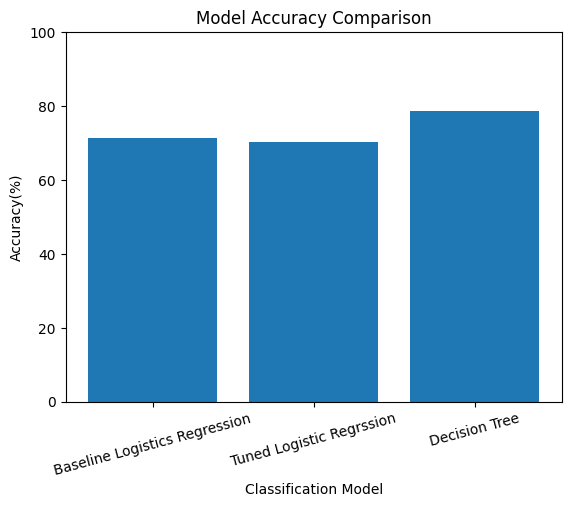

In [63]:
import matplotlib.pyplot as plt

models = ['Baseline Logistics Regression', 'Tuned Logistic Regrssion', 'Decision Tree']

accuracy = [71.43,70.13,78.57]

plt.bar(models,accuracy)

plt.title('Model Accuracy Comparison')
plt.xlabel('Classification Model')
plt.ylabel('Accuracy(%)')
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.show()

The bar chart compares the accuracy of the three classification models of the dataset. Showing the decision tree achieving highest accuracy at 78.57%, then the baseline logistic regression at 71.43%, and the tuned at 70.13%. This indicates that the dicision tree was the best a classifing cases in this dataset.

I created this chart to further explore and visually compare the classifers.


